# ISS 449 MHz Wind Profiler — Curtain Plots

This notebook reads a daily Zarr store and generates a three-panel time-height curtain plot:

1. **Signal-to-noise ratio** (dB) — from the `moments` group
2. **Vertical velocity** (m/s) — from the `moments` group
3. **Wind barbs** colored by wind speed (m/s) — from the `winds_5min` or `winds_30min` group

**What is a Zarr store?**  
A Zarr store is a directory that holds arrays and their metadata —
similar to a NetCDF file. The prof449 converter writes one Zarr store per day,
organized into three groups (`moments`, `winds_5min`, `winds_30min`), one per
data product. Opening a group with `xr.open_zarr()` returns a standard
`xarray.Dataset` — from there it behaves exactly like data opened from NetCDF.

**How to use this notebook:**  
- Python backend dependencies require: aiohttp to allow xarray to read remote HTTPS Zarr stores.
- Run all cells in order.

In [58]:
%matplotlib inline
import os
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

import re
import requests
from urllib.parse import urljoin

In [59]:
# ----------------------------------------------------------------------------
# Returns .zarr stores from an HTTPS directory listing
# ----------------------------------------------------------------------------
def list_https_files(base_url, pattern=r'href="([^"?]+.zarr/?)'):
    r = requests.get(base_url, timeout=60)
    r.raise_for_status()
    return [urljoin(base_url, h) for h in re.findall(pattern, r.text)]

## 1. Configuration

In [60]:
# ----------------------------------------------------------------
# HTTPS configuration for accessing the 449 MHz Zarr dataset
# ----------------------------------------------------------------
# 449 MHz Dataset ID
DSID = "d361534"

# Method: HTTPS Web File Listing
HTTPS_BASE = f"https://osdf-director.osg-htc.org/ncar/gdex/{DSID}/zarr/"

# List all Zarr stores available at the HTTPS base URL
url = list_https_files(HTTPS_BASE)

# Check that we have found the Zarr stores
if not url:
    raise ValueError("No Zarr stores found at the specified HTTPS base URL.")
print(f"Found {len(url)} Zarr stores.")

# Note the beginning date and end date from the file names
begin_date = min(url)
end_date = max(url)
print(f"Beginning file: {os.path.basename(begin_date.rstrip('/'))}")
print(f"End file: {os.path.basename(end_date.rstrip('/'))}")



Found 79 Zarr stores.
Beginning file: m2hats_eol-iss_windradar_449MHz_20230711_v1.zarr
End file: m2hats_eol-iss_windradar_449MHz_20230927_v1.zarr


In [61]:
# ------------------------------------------------------------------------------------------------
# Edit the values below before running. 
# 'WINDS_RESOLUTION` selects whether to use the 5-minute or 30-minute averaged winds for panel 3.
# ------------------------------------------------------------------------------------------------
DATE              = '20230909'   # YYYYMMDD
WINDS_RESOLUTION  = '30min'      # '5min' or '30min'
CAMPAIGN          = 'M2HATS'     # Field campaign name

# Get the Zarr store URL for the current date
ZARR_STORE = f"{HTTPS_BASE}{CAMPAIGN.lower()}_eol-iss_windradar_449MHz_{DATE}_v1.zarr"

MAX_HEIGHT = 6000   # upper height limit in metres MSL

# Color limits — panel 1: signal-to-noise ratio
SNR_VMIN  = -15.0
SNR_VMAX  =  15.0
SNR_CMAP  = 'plasma'

# Color limits — panel 2: vertical velocity
VEL_VMIN  = -2.0
VEL_VMAX  =  2.0
VEL_CMAP  = 'RdBu_r'

# Color limits — panel 3: wind speed background
WSPD_VMIN =  0.0
WSPD_VMAX = 15.0
WSPD_CMAP = 'viridis'

# Output
OUTPUT_DIR  = 'Full path to output directory'
SAVE_FIGURE = False   # True = save PNG to OUTPUT_DIR; False = display inline

## 2. Opening the Zarr store

The daily store contains three groups:
- `moments` — high-rate Doppler data (one time step per radar dwell)
- `winds_5min` or `winds_30min` — time-averaged consensus winds

`consolidated=True` reads the single `.zmetadata` summary file at the store root
rather than opening each variable's metadata file one by one — faster, especially
over a networked filesystem. 

The `height` coordinate is 2-D `(time, height)` in all groups. Heights are constant
across time for this instrument, so `height[0, :]` gives a representative 1-D
height vector for the y-axis. A `MAX_HEIGHT` mask then trims it to the configured
upper limit before plotting.

In [62]:
# Open both groups — each returns a standard xarray Dataset
ds_mom   = xr.open_zarr(ZARR_STORE, group='moments', consolidated=True)
ds_winds = xr.open_zarr(ZARR_STORE, group=f'winds_{WINDS_RESOLUTION}', consolidated=True)

# Time arrays — xarray CF-decodes to datetime64[ns]
time_mom   = ds_mom['time'].values
time_winds = ds_winds['time'].values

# height is 2-D (time, height) in both groups; use the first row as a representative
# 1-D height vector — heights are constant across time for this instrument
height_mom   = ds_mom['height'].values[0, :]
height_winds = ds_winds['height'].values[0, :]

# Build a boolean mask selecting height levels at or below MAX_HEIGHT
# This is used to slice the 2-D (time, height) arrays before plotting to remove empty space
hi_mom   = height_mom   <= MAX_HEIGHT
hi_winds = height_winds <= MAX_HEIGHT

# Extract the science arrays, applying the height mask along the height axis
snr  = ds_mom['sigNoiseRatio'].values[:, hi_mom]
vel  = ds_mom['vel'].values[:, hi_mom]
wspd = ds_winds['wspd'].values[:, hi_winds]
u    = ds_winds['u'].values[:, hi_winds]
v    = ds_winds['v'].values[:, hi_winds]

## 3. Plotting the curtains

A **curtain plot** stacks time along the x-axis and height along the y-axis,
showing how a variable evolves through the day at each altitude level.
`pcolormesh` draws the filled color grid; wind barbs are overlaid on panel 3
using subsampled `u` and `v` components converted from m/s to knots (the
meteorological convention for barb plots).

Wind barbs are subsampled to ~60 time × 15 height points for readability — the
full-resolution data would produce an unreadable dense grid of barbs. The
`[::t_step]` notation means "take every t_step-th element", so the step size
adapts to however many time or height levels are in the dataset.

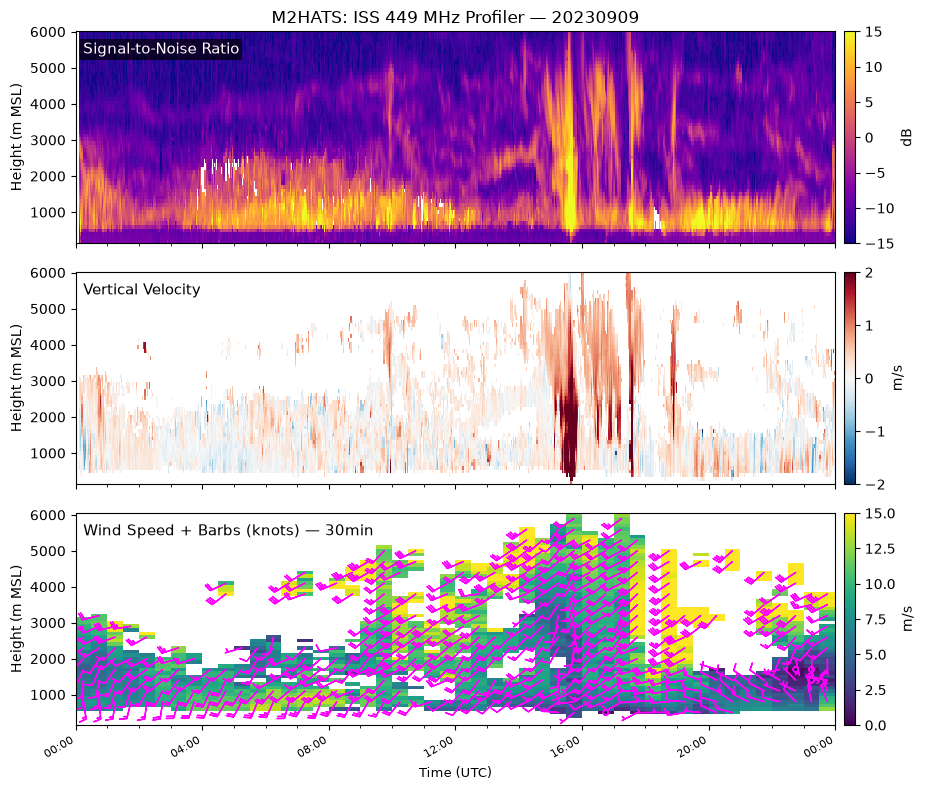

In [63]:
# Wind barb subsampling — target ~60 time × 15 height points regardless of resolution
n_time_winds, n_hgt_winds = u.shape
t_step = max(1, n_time_winds // 60)
h_step = max(1, n_hgt_winds  // 15)

# [::t_step] takes every t_step-th element along that axis
# [::h_step] takes every h_step-th element along that axis
t_sub = time_winds[::t_step]
h_sub = height_winds[:n_hgt_winds][::h_step]
u_sub = u[::t_step, ::h_step]
v_sub = v[::t_step, ::h_step]

# Convert u, v from m/s to knots — meteorological convention for wind barbs
MS_TO_KNOTS = 1.94384
u_kts = u_sub * MS_TO_KNOTS
v_kts = v_sub * MS_TO_KNOTS
# Repeat time and height values across height columns and time rows to create a 2-D grid for wind barb plotting
T_grid, H_grid = np.meshgrid(t_sub, h_sub, indexing='ij')

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
fig.subplots_adjust(hspace=0.06)

# Panel 1: signal-to-noise ratio
# The transpose is important: the snr array is shaped [time, height], 
# but pcolormesh expects [y, x] = [height, time], so .T flips it to align with axes.
pcm1 = ax1.pcolormesh(time_mom, height_mom[hi_mom], snr.T,
                      vmin=SNR_VMIN, vmax=SNR_VMAX, cmap=SNR_CMAP, shading='nearest')
fig.colorbar(pcm1, ax=ax1, label='dB', pad=0.01)
ax1.set_ylabel('Height (m MSL)')
ax1.set_title(f'{CAMPAIGN}: ISS 449 MHz Profiler — {DATE}', fontsize=12)
bbox = dict(facecolor='black', alpha=0.7, pad=2, edgecolor='none')
ax1.text(0.01, 0.95, 'Signal-to-Noise Ratio', transform=ax1.transAxes,
         va='top', fontsize=11, color='white', bbox=bbox)

# Panel 2: vertical velocity
pcm2 = ax2.pcolormesh(time_mom, height_mom[hi_mom], vel.T,
                      vmin=VEL_VMIN, vmax=VEL_VMAX, cmap=VEL_CMAP, shading='nearest')
fig.colorbar(pcm2, ax=ax2, label='m/s', pad=0.01)
ax2.set_ylabel('Height (m MSL)')
ax2.text(0.01, 0.95, 'Vertical Velocity', transform=ax2.transAxes,
         va='top', fontsize=11)

# Panel 3: wind speed background + wind barbs
pcm3 = ax3.pcolormesh(time_winds, height_winds[hi_winds], wspd.T,
                      vmin=WSPD_VMIN, vmax=WSPD_VMAX, cmap=WSPD_CMAP, shading='nearest')
fig.colorbar(pcm3, ax=ax3, label='m/s', pad=0.01)
ax3.barbs(T_grid.flatten(), H_grid.flatten(), u_kts.flatten(), v_kts.flatten(),
          length=5, linewidth=1, color='magenta')
ax3.set_ylabel('Height (m MSL)')
ax3.text(0.01, 0.95, f'Wind Speed + Barbs (knots) — {WINDS_RESOLUTION}',
         transform=ax3.transAxes, va='top', fontsize=11, color='black')

# Shared x-axis formatting applied to bottom panel only
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax3.xaxis.set_major_locator(mdates.HourLocator(interval=4))
ax3.xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 60]))
plt.setp(ax3.get_xticklabels(), rotation=30, ha='right', fontsize=8)
ax3.set_xlabel('Time (UTC)', fontsize=9)

fig.tight_layout()

if SAVE_FIGURE:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    out_path = os.path.join(OUTPUT_DIR, f'{CAMPAIGN}_prof449_{WINDS_RESOLUTION}_{DATE}_curtain.png')
    fig.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f'Saved: {out_path}')
else:
    plt.show()